# PayGuard — démonstration complète

Simulation d'un système de paiement mobile en francs guinéens (GNF) et détection de fraude **par règles métier**
(aucun apprentissage automatique).

Ce notebook est une **vitrine** : il n'écrit aucune logique métier, il appelle uniquement les fonctions et classes
du paquet `payguard` (installé avec `pip install -e .`). Il parcourt les six phases du projet :

| Phase | Contenu | Modules |
|---|---|---|
| 1 | Génération des données synthétiques | `payguard.generation` |
| 2 | Modèle objet, plateforme, atomicité | `payguard.comptes` |
| 3 | Décorateurs, contextes, flux, fenêtre glissante | `payguard.outils` |
| 4 | SQLite, analyse exploratoire, profils | `payguard.donnees` |
| 5 | Moteur de règles, alertes, évaluation, coût | `payguard.detection` |
| 6 | Interface en ligne de commande | `payguard.cli` |

Tous les résultats sont reproductibles : la graine est fixée (42).

In [1]:
from pathlib import Path

import pandas as pd

import payguard
from payguard.journal import configurer_journalisation

# Racine du projet, que le notebook soit lancé depuis notebooks/ ou depuis la racine.
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DONNEES = RACINE / "data" / "notebook"
GRAINE = 42

configurer_journalisation(fichier=DONNEES / "payguard.log", niveau_console="WARNING")
pd.set_option("display.width", 140)
print("PayGuard", payguard.__version__, "| racine :", RACINE)

PayGuard 1.0.0 | racine : /Users/xhalif/Desktop/MasterIASD/payguard


## Phase 1 — Génération des données

Le générateur est écrit en **fonctions** avec la seule bibliothèque standard (`random`, `csv`, `datetime`).
Il produit une population de comptes (particuliers, marchands, agents), des opérations légitimes avec du bruit
réaliste (couche-tard, voyages, changements de téléphone), puis injecte **six scénarios de fraude**.

In [2]:
from payguard.generation.generateur import generer_jeu_de_donnees
from payguard.generation.scenarios import SCENARIOS

resume = generer_jeu_de_donnees(
    DONNEES / "brut.csv", chemin_scenarios=DONNEES / "brut_scenarios.csv", graine=GRAINE
)
print(f"{resume['nb_transactions']} transactions, {resume['nb_fraudes']} fraudes "
      f"({resume['taux_fraude']:.2%}), du {resume['debut']} au {resume['fin']}")
print("Scénarios disponibles :", ", ".join(SCENARIOS))
pd.Series(resume["par_scenario"], name="fraudes par scénario").to_frame()

123142 transactions, 1830 fraudes (1.49%), du 2026-01-01T00:11:40 au 2026-06-30T23:54:49
Scénarios disponibles : montant_eleve, rafale, horaire_inhabituel, changement_zone, compte_neuf_vide, nouvel_appareil


,fraudes par scénario
horaire_inhabituel,250
nouvel_appareil,186
changement_zone,171
montant_eleve,153
compte_neuf_vide,452
rafale,618


In [3]:
pd.read_csv(DONNEES / "brut.csv", nrows=5)

,id_transaction,horodatage,id_emetteur,id_destinataire,type,montant,zone,appareil_id,est_fraude
0,TX00000001,2026-01-01T00:11:40,P000686,M000051,paiement_marchand,19000,Conakry,APP-35831D71,0
1,TX00000002,2026-01-01T00:15:19,P001384,P002834,transfert,153000,Kankan,APP-5B034D52,0
2,TX00000003,2026-01-01T00:15:52,P000291,M000329,paiement_marchand,57500,Kindia,APP-65ED7ECC,0
3,TX00000004,2026-01-01T00:16:07,P001384,M000280,paiement_marchand,7500,Kankan,APP-5B034D52,0
4,TX00000005,2026-01-01T00:42:22,A000051,P003202,depot,685000,Conakry,APP-BF5AE7E6,0


Le générateur valide ses paramètres et lève une exception explicite :

In [4]:
from payguard.exceptions import ParametreInvalide
from payguard.generation.generateur import generer_transactions

try:
    generer_transactions(taux_fraude=0.5)
except ParametreInvalide as erreur:
    print("ParametreInvalide :", erreur)

ParametreInvalide : taux_fraude doit être un nombre entre 0 et 0,2 (reçu : 0.5)


## Phase 2 — Modèle orienté objet

* `Compte` est une classe **abstraite** ; `ComptePersonnel`, `CompteMarchand`, `CompteAgent` fournissent leurs
  plafonds, frais et types d'opérations (méthodes **polymorphes**).
* `Client` valide ses attributs par des **propriétés** (numéro guinéen +224 6XX XX XX XX, nom non vide).
* `Transaction` est une dataclass **figée** ; `TypeTransaction` une énumération.
* `Plateforme` **compose** un registre de comptes et exécute les opérations de façon **atomique**.

In [5]:
from payguard.comptes import (Client, CompteAgent, CompteMarchand, ComptePersonnel, Plateforme,
                              TypeTransaction)

plateforme = Plateforme()
aissatou = plateforme.ouvrir_compte(ComptePersonnel("P1", Client("C1", "Aïssatou Bah", "620 11 22 33"), 1_000_000))
mamadou = plateforme.ouvrir_compte(ComptePersonnel("P2", Client("C2", "Mamadou Camara", "+224655443322"), 50_000))
boutique = plateforme.ouvrir_compte(CompteMarchand("M1", Client("C3", "Boutique Kaloum", "00224622000111")))
agent = plateforme.ouvrir_compte(CompteAgent("A1", Client("C4", "Agent Madina", "664000111"), 10_000_000))

for compte in plateforme:
    print(f"{compte!r:75}  frais retrait 100 000 GNF : {compte.calculer_frais(TypeTransaction.RETRAIT, 100_000)}")

ComptePersonnel(id_compte='P1', titulaire='Aïssatou Bah', solde=1000000)     frais retrait 100 000 GNF : 1500
ComptePersonnel(id_compte='P2', titulaire='Mamadou Camara', solde=50000)     frais retrait 100 000 GNF : 1500
CompteMarchand(id_compte='M1', titulaire='Boutique Kaloum', solde=0)         frais retrait 100 000 GNF : 1000
CompteAgent(id_compte='A1', titulaire='Agent Madina', solde=10000000)        frais retrait 100 000 GNF : 0


In [6]:
plateforme.transferer("P1", "P2", 200_000)
plateforme.payer("P2", "M1", 75_000)
plateforme.retirer("P1", "A1", 100_000)
print(plateforme)
print("Soldes :", {c.id_compte: c.solde for c in plateforme}, "| frais encaissés :", plateforme.revenus)
print("Tri naturel (par identifiant) :", [c.id_compte for c in sorted(plateforme.comptes)])
print("Particuliers triés par solde :",
      [(c.id_compte, c.solde) for c in plateforme.comptes.par_type(ComptePersonnel).tries(lambda c: c.solde)])

Plateforme(nom='PayGuard', comptes=4, transactions=3, revenus=3500)
Soldes : {'P1': 696500, 'P2': 175000, 'M1': 75000, 'A1': 10100000} | frais encaissés : 3500
Tri naturel (par identifiant) : ['A1', 'M1', 'P1', 'P2']
Particuliers triés par solde : [('P2', 175000), ('P1', 696500)]


**Atomicité.** On gèle le destinataire : le débit de l'émetteur réussit, puis le crédit échoue.
Le gestionnaire de contexte restaure l'état initial — aucun franc n'est perdu.

In [7]:
from payguard.exceptions import CompteGele, SoldeInsuffisant

avant = {c.id_compte: c.solde for c in plateforme}
mamadou.geler()
try:
    plateforme.transferer("P1", "P2", 300_000)
except CompteGele as erreur:
    print("Refusé :", erreur)
print("Soldes inchangés :", avant == {c.id_compte: c.solde for c in plateforme})
mamadou.degeler()

try:
    plateforme.transferer("P2", "P1", 5_000_000)
except SoldeInsuffisant as erreur:
    print("Refusé :", erreur)
print("Rejets comptés par la plateforme :", dict(plateforme.rejets))

Refusé : Le compte P2 est gelé
Soldes inchangés : True
Refusé : Solde insuffisant sur P2 : 175000 GNF disponibles, 5050000 GNF requis (frais inclus)
Rejets comptés par la plateforme : {'CompteGele': 1, 'SoldeInsuffisant': 1}


**Le générateur refondu alimente la plateforme** : chaque opération générée est exécutée par `Plateforme.executer`
et doit respecter soldes, plafonds et types autorisés. Les opérations refusées sont comptées par motif.

In [8]:
from payguard.generation.simulation import ecrire_scenarios, ecrire_transactions, simuler

simulation = simuler(graine=GRAINE)
ecrire_transactions(simulation.transactions, DONNEES / "transactions.csv")
ecrire_scenarios(simulation.scenarios, DONNEES / "scenarios.csv")
pd.Series(simulation.resume(), name="simulation").to_frame()

,simulation
nb_transactions_acceptees,122927
nb_rejets,215
rejets_par_motif,{'SoldeInsuffisant': 215}
rejets_frauduleux,1
nb_fraudes,1829
taux_fraude,0.014879
revenus_plateforme,250384384
nb_comptes,5000


## Phase 3 — Python avancé

Décorateurs (`@chronometre`, `@journaliser`, `@reessayer(n, delai)`), gestionnaire de contexte en deux versions
(classe et `contextlib`), générateur de lecture par blocs, itérateur de fenêtre glissante.

In [9]:
from payguard.outils.decorateurs import chronometre

print(f"simuler() a duré {simuler.derniere_duree:.2f} s (mesuré par @chronometre)")
print("Métadonnées préservées par functools.wraps :", simuler.__name__, "|", simuler.__doc__.splitlines()[0])

simuler() a duré 1.43 s (mesuré par @chronometre)
Métadonnées préservées par functools.wraps : simuler | Génère comptes et opérations puis les exécute sur la plateforme.


In [10]:
from payguard.outils.contextes import TransactionAtomique, transaction_atomique

compte = ComptePersonnel("X", Client("CX", "Test", "620000000"), 10_000)
for gestionnaire in (TransactionAtomique, transaction_atomique):
    try:
        with gestionnaire(compte):
            compte.debiter(5_000, TypeTransaction.PAIEMENT_MARCHAND, pd.Timestamp("2026-03-01").to_pydatetime())
            raise RuntimeError("panne au milieu de l'opération")
    except RuntimeError:
        pass
    print(f"{gestionnaire.__name__:22} -> solde restauré : {compte.solde}")

TransactionAtomique    -> solde restauré : 10000
transaction_atomique   -> solde restauré : 10000


In [11]:
from datetime import timedelta
from itertools import islice

from payguard.outils.flux import FenetreGlissanteParCompte, RapportLecture, lire_par_blocs, lire_transactions

rapport = RapportLecture()
tailles = [len(bloc) for bloc in lire_par_blocs(DONNEES / "transactions.csv", taille_bloc=25_000, rapport=rapport)]
print("Blocs lus sans charger le fichier :", tailles, "|", rapport)

fenetres = FenetreGlissanteParCompte(lire_transactions(DONNEES / "transactions.csv"), taille=3,
                                     duree=timedelta(minutes=10), completes_seulement=True)
compte, fenetre = next(fenetres)
print(f"Première fenêtre complète (3 opérations en 10 min) : compte {compte}")
for t in fenetre:
    print("   ", t.horodatage, t.type.value, t.montant, "fraude" if t.est_fraude else "")

Blocs lus sans charger le fichier : [25000, 25000, 25000, 25000, 22927] | RapportLecture(lues=122927, rejetees=0, etiquette_presente=True)
Première fenêtre complète (3 opérations en 10 min) : compte P001360
    2026-01-06 15:26:25 transfert 190000 fraude
    2026-01-06 15:26:46 transfert 272500 fraude
    2026-01-06 15:29:13 transfert 138500 fraude


## Phase 4 — Persistance et analyse

La classe `Depot` est le seul endroit du projet qui contient du SQL (requêtes paramétrées, insertion par lots).

In [12]:
from payguard.donnees.depot import Depot

with Depot(DONNEES / "payguard.db") as depot:
    depot.vider()
    depot.inserer_transactions(simulation.transactions, taille_lot=5_000)
    depot.inserer_comptes(simulation.plateforme.comptes)
    print("Transactions en base :", depot.compter_transactions())
    print("Historique du compte P000001 :", sum(1 for _ in depot.transactions(id_compte="P000001")), "opérations")
    df = depot.lire_dataframe()
pd.DataFrame(Depot(DONNEES / "payguard.db").statistiques_par_type()).T

Transactions en base : 122927
Historique du compte P000001 : 9 opérations


,nombre,volume,taux_fraude
depot,33481.0,2.167348e+10,0.000000
paiement_marchand,25865.0,1.905639e+09,0.005413
retrait,25849.0,1.219669e+10,0.020658
transfert,37732.0,1.021975e+10,0.030611


In [13]:
from payguard.donnees import analyse

resultats = analyse.analyser(df)
print(f"Taux de fraude global : {resultats['taux_fraude_global']:.2%}")
resultats["montants_par_type"][["count", "25%", "50%", "75%", "99%"]].round(0)

Taux de fraude global : 1.49%


,count,25%,50%,75%,99%
type,,,,,
depot,33481.0,166000.0,347000.0,743500.0,4874900.0
retrait,25849.0,121500.0,256000.0,538000.0,3570660.0
transfert,37732.0,63500.0,140000.0,304500.0,2050190.0
paiement_marchand,25865.0,25000.0,46500.0,87500.0,448180.0


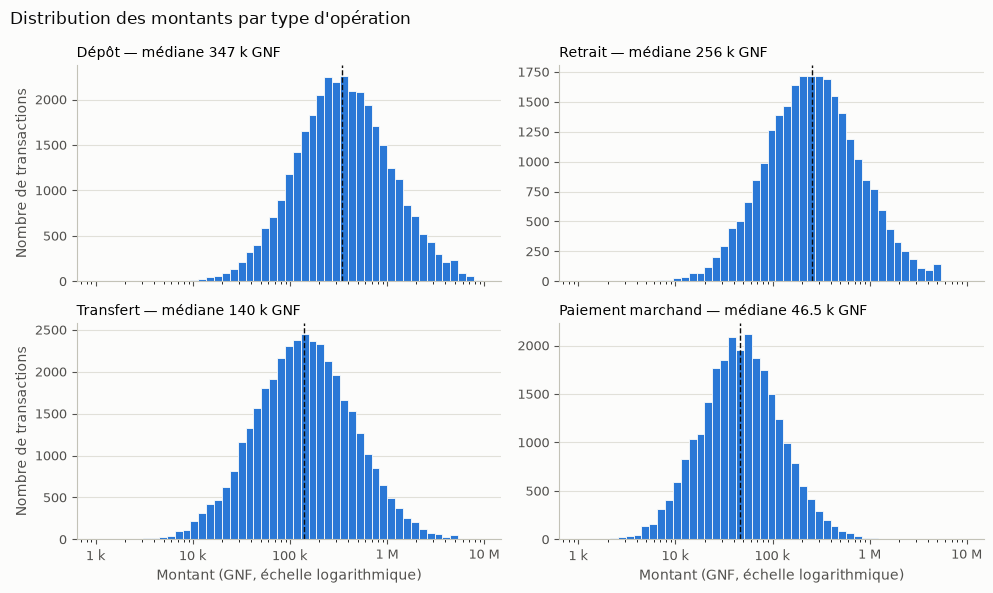

In [14]:
analyse.tracer_montants_par_type(df);

**Q2 — Fraude par heure et par zone.** Le taux de fraude est 5 à 8 fois plus élevé entre 0 h et 5 h ; les zones
diffèrent peu (la zone seule n'est pas un bon signal : c'est le *changement* de zone qui compte).

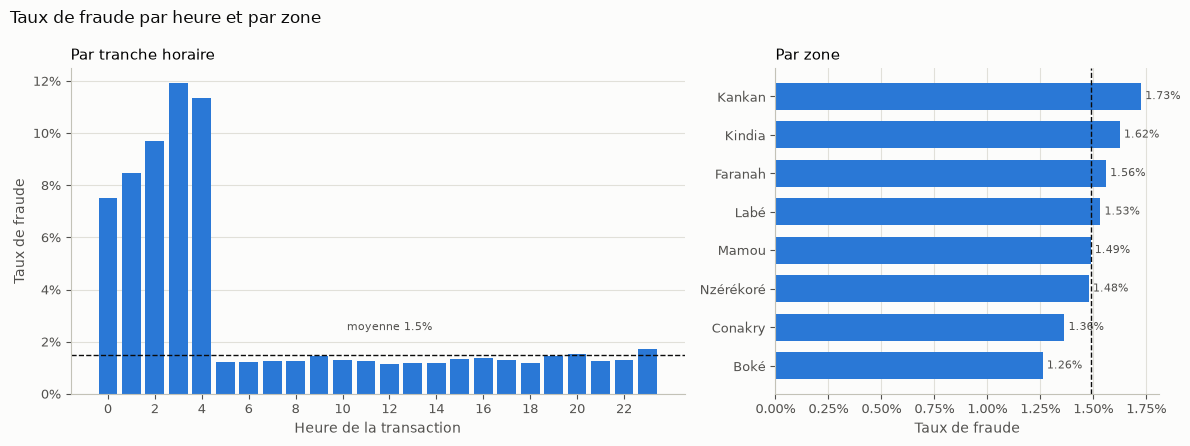

In [15]:
analyse.tracer_taux_fraude_heure_zone(df);

**Q3 — Concentration.** Le centile de comptes le plus actif porte une part du volume bien supérieure à 1 % :
ce sont surtout des agents (dépôts) — un seuil de montant unique ne peut pas convenir à tous les comptes.

{'nb_comptes_emetteurs': 4882, 'nb_comptes_retenus': 49, 'part_volume_plus_actifs': 0.19549042955367255, 'part_operations_plus_actifs': 0.12240598078534415, 'part_volume_plus_gros_volumes': 0.21100314560824093, 'types_comptes_plus_actifs': {'A': np.int64(43), 'P': np.int64(5), 'M': np.int64(1)}}


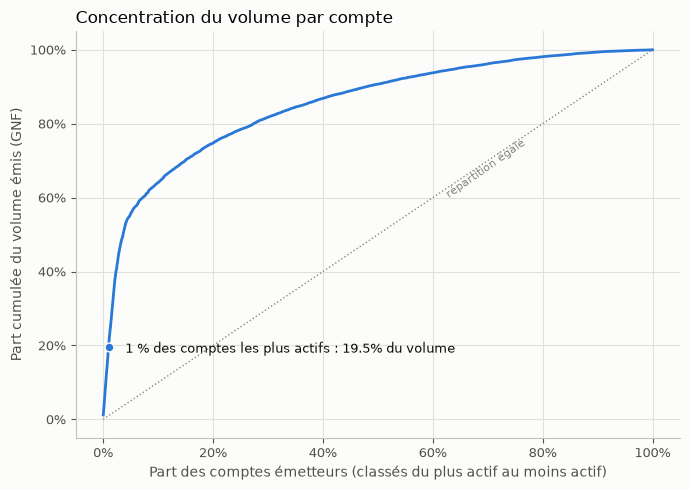

In [16]:
print(resultats["concentration"])
analyse.tracer_courbe_concentration(df);

**Q4 — Délai entre transactions.** Les fraudes suivent de beaucoup plus près l'opération précédente du compte
(rafales, voyages impossibles, comptes vidés aussitôt) : c'est la justification des règles *rafale* et *changement de zone*.

,transactions,delai_median_min,premier_quartile_min,troisieme_quartile_min
est_fraude,,,,
légitime,83060,4401.0,1470.9,11660.2
frauduleuse,1654,610.2,2.4,10140.5


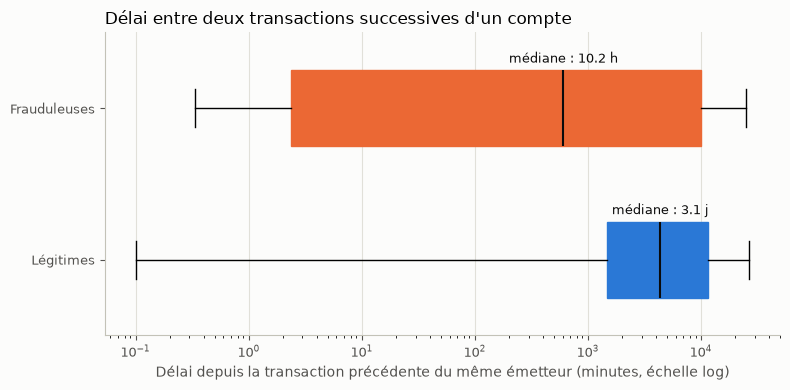

In [17]:
display(resultats["delai_median"].round(1))
analyse.tracer_delai_median(df);

**Q5 — Ancienneté.** Les comptes apparus depuis moins d'une semaine fraudent nettement plus
(les 30 premiers jours sont écartés : tous les comptes y paraissent « nouveaux »).

**Q6 — Question libre : appareil jamais vu.** Une opération depuis un appareil inconnu du compte est frauduleuse
dans environ 40 % des cas, contre environ 1 % sinon : signal fort, mais qui touche aussi des clients ayant changé de téléphone.

,transactions,fraudes,taux_fraude
tranche,,,
< 1 jour,187,9,0.048128
1 à 7 jours,164,10,0.060976
7 à 30 jours,2538,62,0.024429
30 à 90 jours,40435,563,0.013924
> 90 jours,61161,989,0.016170


,transactions,fraudes,taux_fraude,part_des_fraudes
appareil,,,,
appareil connu,117045,1242,0.010611,0.750907
nouvel appareil,1000,412,0.412000,0.249093


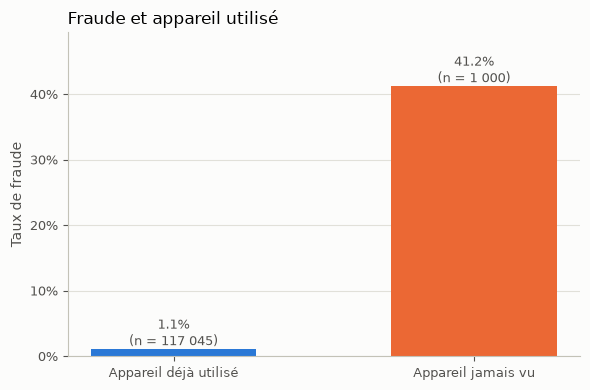

In [18]:
display(resultats["fraude_par_anciennete"])
display(resultats["fraude_nouvel_appareil"])
analyse.tracer_fraude_nouvel_appareil(df);

**Profils de comptes : Python pur contre pandas.** Les deux implémentations donnent des objets égaux (`==`) ;
on mesure ensuite leurs temps (meilleur de 3 essais, données déjà en mémoire).

In [19]:
from payguard.donnees.profils import ProfilsComptes, comparer_implementations

transactions = sorted(simulation.transactions)
mesure = comparer_implementations(transactions, df, repetitions=3)
display(pd.Series(mesure).to_frame("mesure"))
ProfilsComptes.calculer_python(transactions).vers_dataframe().head()

,mesure
nb_transactions,122927
nb_comptes,4999
identiques,True
repetitions,3
python_s,0.105869
pandas_complet_s,0.114907
pandas_agregation_s,0.081641
acceleration_complet,0.921343
acceleration_agregation,1.296768


,nb_operations,montant_moyen,montant_max,heure_principale,nb_zones,zone_principale,nb_appareils,nb_receptions,total_recu,premiere_apparition
id_compte,,,,,,,,,,
P000686,97,222649.48,2600000,17.0,4,Conakry,2,37,21239500,2026-01-01 00:11:40
M000051,7,1774928.57,4006500,13.0,1,Conakry,1,50,16284000,2026-01-01 00:11:40
P001384,79,182677.22,1238500,0.0,4,Kankan,1,40,16956000,2026-01-01 00:15:19
P002834,24,119520.83,546500,12.0,2,Labé,1,25,7544000,2026-01-01 00:15:19
P000291,35,166942.86,965000,18.0,3,Kindia,2,15,6707500,2026-01-01 00:15:52


## Phase 5 — Moteur de détection par règles

* `Regle` (abstraite) impose `evaluer(transaction, profil)` ; chaque règle renvoie *déclenchée ou non*, un poids et un motif lisible.
* `MoteurDeRegles` applique une liste de règles interchangeables (patron **Stratégie**) ; score = somme des poids.
* Les profils sont **causaux** : chaque transaction est jugée avec le passé de son émetteur uniquement ;
  l'étiquette `est_fraude` n'est jamais lue par le moteur.
* La configuration (règles actives, seuils, poids, score d'alerte) vient d'un fichier JSON validé.

In [20]:
from payguard.detection import charger_configuration

configuration = charger_configuration(RACINE / "config" / "regles.json")
moteur = configuration.construire_moteur()
print(moteur, "\n")
for regle in moteur:
    print(f"  {regle.identifiant:22} poids {regle.poids:g}  {regle.parametres()}")

MoteurDeRegles(seuil_alerte=2, regles=[montant_anormal, rafale, horaire_inhabituel, changement_zone, nouvel_appareil, compte_recent_vide, montant_significatif, montant_eleve]) 

  montant_anormal        poids 1  {'facteur': 4.0, 'min_operations': 3, 'montant_minimum': 100000, 'types_operations': None}
  rafale                 poids 2  {'nb_operations': 2, 'fenetre_minutes': 5.0, 'types_operations': None}
  horaire_inhabituel     poids 1  {'heure_debut': 0, 'heure_fin': 5, 'part_max': 0.1, 'types_operations': None}
  changement_zone        poids 1  {'delai_minutes': 180.0, 'min_operations': 5, 'part_min': 0.0, 'types_operations': None}
  nouvel_appareil        poids 2  {'min_operations': 2, 'types_operations': None}
  compte_recent_vide     poids 1  {'anciennete_max_jours': 7.0, 'part_min': 0.8, 'montant_minimum': 50000, 'types_operations': None}
  montant_significatif   poids 1  {'seuil': 50000, 'types_operations': ['paiement_marchand', 'retrait', 'transfert']}
  montant_eleve         

In [21]:
evaluations = list(moteur.analyser(transactions))
alertes = [e for e in evaluations if e.est_alerte(moteur.seuil_alerte)]
print(f"{len(alertes)} alertes sur {len(evaluations)} transactions\n")
from payguard.detection import Alerte
plus_suspectes = sorted((Alerte.depuis_evaluation(e) for e in alertes), reverse=True)[:3]
for alerte in plus_suspectes:
    print(alerte, "\n")

40879 alertes sur 122927 transactions

[ALERTE] TX00121413 | 2026-06-28 16:08:43 | paiement_marchand | 739 000 GNF | P003292 -> M000479 | score 6
    - montant_anormal : montant 739 000 GNF = 7.3 × la moyenne du compte (100 944 GNF), au-delà de son maximum (563 000 GNF)
    - changement_zone : zone Nzérékoré jamais ou rarement utilisée par le compte (0/18 opérations)
    - nouvel_appareil : appareil APP-E4E5F93E jamais utilisé par le compte (2 appareil(s) connu(s), 18 opérations)
    - montant_significatif : montant 739 000 GNF >= seuil de 50 000 GNF
    - montant_eleve : montant 739 000 GNF >= seuil de 150 000 GNF 

[ALERTE] TX00115036 | 2026-06-19 22:24:20 | transfert | 306 500 GNF | P001928 -> P001723 | score 6
    - montant_anormal : montant 306 500 GNF = 5.3 × la moyenne du compte (57 722 GNF), au-delà de son maximum (150 500 GNF)
    - changement_zone : zone Faranah jamais ou rarement utilisée par le compte (0/9 opérations)
    - nouvel_appareil : appareil APP-66965A20 jamais uti

**Évaluation et coût métier.** Une fraude manquée coûte son montant, une alerte injustifiée 500 GNF.
L'exactitude est affichée pour montrer qu'elle est trompeuse : « ne rien signaler » atteint 98,5 %.

In [22]:
from payguard.detection.evaluation import (detection_par_scenario, evaluer, evolution_mensuelle,
                                           references)

reglages = {
    "retenu (coût minimal)": RACINE / "config" / "regles.json",
    "équilibré": RACINE / "config" / "reglages" / "equilibre.json",
    "prudent": RACINE / "config" / "reglages" / "prudent.json",
}
rapports = list(references(transactions))
for nom, chemin in reglages.items():
    m = charger_configuration(chemin).construire_moteur()
    signales = {e.transaction.id_transaction for e in m.analyser(transactions) if e.est_alerte(m.seuil_alerte)}
    rapports.append(evaluer(transactions, signales, nom=nom))
tableau = pd.DataFrame([r.vers_dict() for r in rapports]).set_index("reglage")
tableau[["alertes", "fraudes_detectees", "fraudes_manquees", "fausses_alertes", "taux_detection",
         "precision", "exactitude", "cout_total"]]

,alertes,fraudes_detectees,fraudes_manquees,fausses_alertes,taux_detection,precision,exactitude,cout_total
reglage,,,,,,,,
référence : aucune alerte,0,0,1829,0,0.000000,0.000000,0.985121,949141500
référence : tout signaler,122927,1829,0,121098,1.000000,0.014879,0.014879,60549000
retenu (coût minimal),40879,1743,86,39136,0.952980,0.042638,0.680933,27281500
équilibré,9595,1266,563,8329,0.692182,0.131944,0.927664,215359500
prudent,1945,872,957,1073,0.476763,0.448329,0.983486,583988500


In [23]:
signales = {e.transaction.id_transaction for e in alertes}
pd.DataFrame(detection_par_scenario(evaluations, signales, simulation.scenarios)).T

,fraudes,detectees,taux_detection,montant_manque
changement_zone,170.0,168.0,0.988235,50500.0
compte_neuf_vide,452.0,428.0,0.946903,2320500.0
horaire_inhabituel,250.0,240.0,0.960000,778500.0
montant_eleve,153.0,144.0,0.941176,476000.0
nouvel_appareil,186.0,183.0,0.983871,232500.0
rafale,618.0,580.0,0.938511,3855500.0


In [24]:
mensuel = pd.DataFrame([r.vers_dict() for r in evolution_mensuelle(evaluations, moteur.seuil_alerte)])
mensuel.set_index("reglage")[["alertes", "taux_detection", "precision", "cout_total"]]

,alertes,taux_detection,precision,cout_total
reglage,,,,
2026-01,6348,0.948980,0.029301,4007500
2026-02,5859,0.928889,0.035672,4071000
2026-03,6882,0.953069,0.038361,4422000
2026-04,6976,0.956522,0.044151,4585500
2026-05,7386,0.949853,0.043596,5106500
2026-06,7428,0.965957,0.061120,5089000


**Lecture des résultats.** Avec un coût de 500 GNF par fausse alerte, une fraude manquée moyenne (≈ 520 000 GNF)
vaut environ mille fausses alertes : le réglage qui minimise le coût signale toute sortie d'argent d'au moins
150 000 GNF et exige un indice comportemental entre 50 000 et 150 000 GNF. Il divise le coût par 35 par rapport
à l'absence de détection et par plus de 2 par rapport à « tout signaler ». Son prix est un volume d'alertes élevé
(≈ un tiers des transactions), acceptable seulement si une alerte est traitée automatiquement (par exemple une
confirmation par code envoyé au client). Le réglage *prudent* convient si les alertes sont examinées par des humains.

## Phase 6 — Interface en ligne de commande

Les mêmes traitements sont accessibles par `payguard generer | simuler | analyser | detecter | evaluer`.
Simulons la soutenance : un fichier **inconnu**, sans colonne `est_fraude`, dans le désordre.

In [25]:
from payguard.cli import main

inconnu = pd.read_csv(DONNEES / "brut.csv").drop(columns="est_fraude").sample(frac=1, random_state=0).head(20_000)
inconnu.to_csv(DONNEES / "inedit.csv", index=False)

code_sortie = main(["--journal", str(DONNEES / "cli.log"), "detecter", str(DONNEES / "inedit.csv"),
                    "-c", str(RACINE / "config" / "regles.json"), "-o", str(DONNEES / "alertes.csv"),
                    "--limite", "5", "--details"])
print("code de sortie :", code_sortie)

Détection sur /Users/xhalif/Desktop/MasterIASD/payguard/data/notebook/inedit.csv — MoteurDeRegles(seuil_alerte=2, regles=[montant_anormal, rafale, horaire_inhabituel, changement_zone, nouvel_appareil, compte_recent_vide, montant_significatif, montant_eleve]) (/Users/xhalif/Desktop/MasterIASD/payguard/config/regles.json)
[ALERTE] TX00000007 | 2026-01-01 00:53:37 | transfert | 259 500 GNF | P002044 -> P001943 | score 3
    - horaire_inhabituel : opération à 00:53, plage 0 h-5 h représentant 0% de l'historique du compte
    - montant_significatif : montant 259 500 GNF >= seuil de 50 000 GNF
    - montant_eleve : montant 259 500 GNF >= seuil de 150 000 GNF
[ALERTE] TX00000015 | 2026-01-01 02:13:45 | transfert | 311 500 GNF | P001592 -> P003364 | score 3
    - horaire_inhabituel : opération à 02:13, plage 0 h-5 h représentant 0% de l'historique du compte
    - montant_significatif : montant 311 500 GNF >= seuil de 50 000 GNF
    - montant_eleve : montant 311 500 GNF >= seuil de 150 000 GNF


In [26]:
pd.read_csv(DONNEES / "alertes.csv").head()

,id_transaction,horodatage,id_emetteur,id_destinataire,type,montant,score,regles,motifs
0,TX00000007,2026-01-01T00:53:37,P002044,P001943,transfert,259500,3,horaire_inhabituel|montant_significatif|montan...,"opération à 00:53, plage 0 h-5 h représentant ..."
1,TX00000015,2026-01-01T02:13:45,P001592,P003364,transfert,311500,3,horaire_inhabituel|montant_significatif|montan...,"opération à 02:13, plage 0 h-5 h représentant ..."
2,TX00000018,2026-01-01T02:47:52,P000235,P002433,transfert,157000,3,horaire_inhabituel|montant_significatif|montan...,"opération à 02:47, plage 0 h-5 h représentant ..."
3,TX00000026,2026-01-01T06:40:03,P001877,A000089,retrait,507500,2,montant_significatif|montant_eleve,montant 507 500 GNF >= seuil de 50 000 GNF ; m...
4,TX00000052,2026-01-01T08:48:10,P002490,P001595,transfert,191000,2,montant_significatif|montant_eleve,montant 191 000 GNF >= seuil de 50 000 GNF ; m...


## Conclusion

* Les six phases sont implémentées dans le paquet ; ce notebook n'a fait qu'appeler la bibliothèque.
* Les résultats sont reproductibles (graine 42) et les mêmes commandes existent en CLI.
* Limites principales : données synthétiques (les scénarios sont connus de l'équipe qui écrit les règles),
  seuils de montant absolus en GNF, ancienneté estimée par la première apparition dans les données.
  Elles sont discutées dans le README et le rapport.